In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from utils.linear_model import get_ODR, get_OLS

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = 10**np.random.normal(0, 0.3, N) - 1
y = k * x + b + np.random.normal(0, sig, N)

y_err = np.abs(y) / np.random.uniform(2, 4, size=N)
y_obs = y + np.random.normal(0, y_err, N)

x_err = np.abs(x) / np.random.uniform(3, 5, size=N)
x_obs = x + np.random.normal(0, x_err, N)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [ ]:
res_ODR = get_ODR(x_obs, y_obs)
res_wODR = get_ODR(x_obs, y_obs, x_err=x_err, y_err=y_err)
res_OLS = get_OLS(x_obs, y_obs)

2026-11-24 19:52:01.675540: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


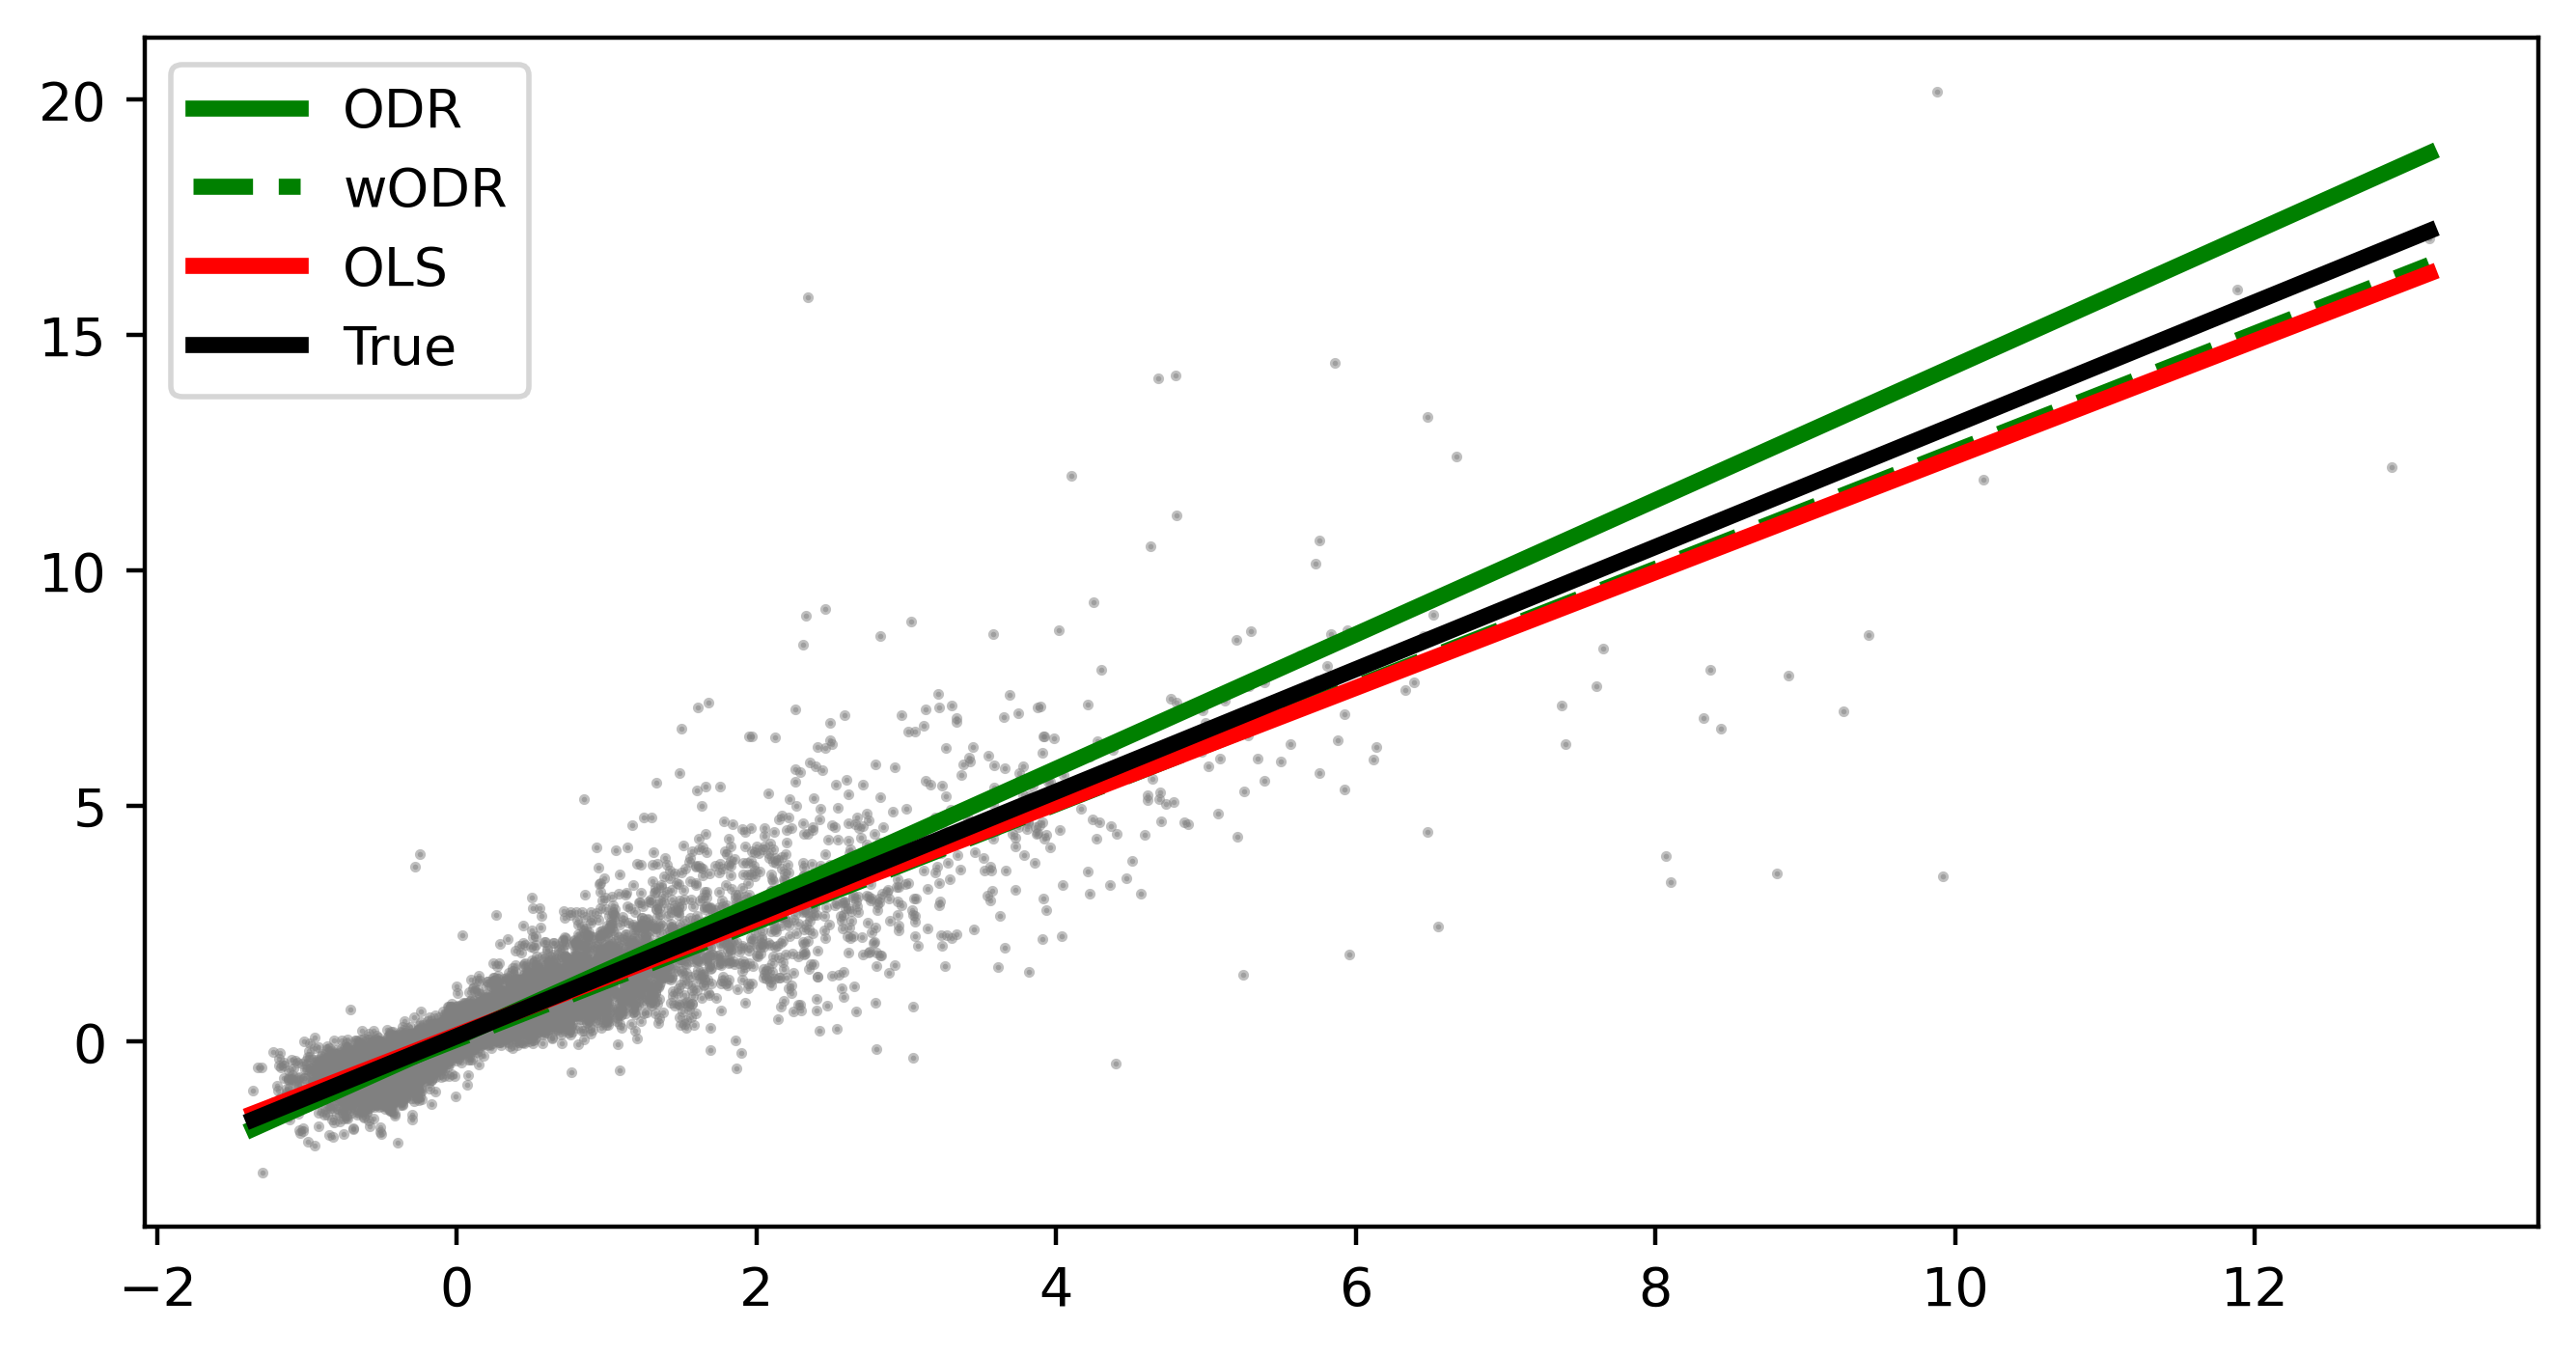

In [ ]:
plt.figure(figsize=(8, 4), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(x_obs.min(), x_obs.max(), 100)
yy = k * xx + b
yy_ODR = res_ODR['func_xy'](xx)
yy_wODR = res_wODR['func_xy'](xx)
yy_OLS = res_OLS['func'](xx)

plt.plot(xx, yy_ODR, color='green', label='ODR', linestyle='-', lw=3)
plt.plot(xx, yy_wODR, color='green', label='wODR', linestyle='--', lw=3)
plt.plot(xx, yy_OLS, color='red', label='OLS', linestyle='-', lw=3)
plt.plot(xx, yy, color='black', label='True', lw=3)

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LinearML, LinearKS
import optax

In [ ]:
xflow = FlowVI(x_min=x_obs.min(),
               x_max=x_obs.max(),
               x_err_min=x_err.min() * 0.8,
               x_err_max=x_err.max() * 1.2,
               transfer=None)

xflow.fit(x_obs,
          x_err,
          verbose=True,
          n_pre=500,
          max_stuck=20,
          stuck_frac=0.02,
          optimizer=optax.adam(3e-4))

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 1/500 [00:06<50:02,  6.02s/it]

  1%|▏         | 7/500 [00:06<05:17,  1.55it/s]

  3%|▎         | 14/500 [00:06<02:10,  3.73it/s]

  4%|▍         | 21/500 [00:06<01:12,  6.57it/s]

  6%|▌         | 28/500 [00:06<00:46, 10.22it/s]

... (75 outputs left out)

step 170: loss -1.0710371732711792
step 180: loss -1.0727983713150024


step 190: loss -1.072442650794983
step 200: loss -1.0713297128677368


step 210: loss -1.0702636241912842
step 220: loss -1.0731841325759888


step 230: loss -1.0759501457214355
step 240: loss -1.0767312049865723


In [ ]:
xflow.ks_test(x_obs, x_err, N=10000)

(0.014400014653801918, 0.4142904903251183)

In [ ]:
yflow = FlowVI(x_min=y_obs.min(),
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2)

yflow.fit(y_obs,
          y_err,
          verbose=True,
          n_pre=1000,
          max_stuck=10,
          stuck_frac=0.02)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:05<1:34:48,  5.69s/it]

  1%|          | 8/1000 [00:05<08:47,  1.88it/s]  

  2%|▏         | 15/1000 [00:05<03:56,  4.17it/s]

  2%|▏         | 22/1000 [00:06<02:16,  7.15it/s]

  3%|▎         | 28/1000 [00:06<01:33, 10.36it/s]

... (145 outputs left out)

step 160: loss 0.09806481748819351
step 170: loss 0.08799660950899124


step 180: loss 0.08744106441736221
step 190: loss 0.0860745906829834


step 200: loss 0.09703411906957626
step 210: loss 0.09485990554094315


step 220: loss 0.08652116358280182
step 230: loss 0.08874353021383286


In [ ]:
yflow.ks_test(y_obs, y_err, N=10000)

(0.020949997007846832, 0.07573155266193173)

### ML Based Method

In [ ]:
from scipy.stats import qmc
from corner import corner

In [ ]:
linear_ML = LinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1.0, 0., 0.1],
    int_method='ghq',
    ignore_y_err_c_y=True,
    n=51,
    flow_batch_size=500_000,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0001922 0.0026957514 0.105194695 1.5601403


1000 1.1938174 0.099123694 0.19394185 1.8177968


2000 1.2132192 0.100718416 0.19532634 1.818348


3000 1.2149194 0.10085484 0.19546145 1.8183523
converged, so stop with 3000 iterations


In [ ]:
params_ml, params_std, cov = linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1.0, 0., 0.1],
    int_method='qgrid',  # different integration method
    ignore_y_err_c_y=True,
    n=51,
    flow_batch_size=500_000,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0002037 0.0025949944 0.105511494 -0.019742006


1000 1.099134 0.08662307 0.17397177 0.26782095


2000 1.099134 0.08662307 0.17397177 0.26782095
converged, so stop with 2000 iterations


In [ ]:
params_ml, params_std, cov = linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1.0, 0., 0.1],
    int_method='auto',
    ignore_y_err_c_y=True,
    n=51,
    flow_batch_size=500_000,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0001922 0.0026957514 0.105194695 1.5601403


1000 1.1938174 0.099123694 0.19394185 1.8177968


2000 1.2132192 0.100718416 0.19532634 1.818348


3000 1.2149194 0.10085484 0.19546145 1.8183523
converged, so stop with 3000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.2149194 0.10085484 0.19546145
Truth: 1.3 0.1 0.2


In [ ]:
sampler = qmc.Sobol(d=3, scramble=True)
l_bounds = [
    max(params_ml[0] - 0.02, -2),
    max(params_ml[1] - 0.02, -2),
    max(params_ml[2] - 0.02, 0.1)
]
u_bounds = [
    min(params_ml[0] + 0.02, 2),
    min(params_ml[1] + 0.02, 2),
    min(params_ml[2] + 0.02, 0.5)
]
params_grid = qmc.scale(sampler.random_base2(m=15), l_bounds, u_bounds)

log_posterior = linear_ML.log_posterior(x_obs, x_err, y_obs,
                                                     y_err, params_grid)

weight = jnp.exp(log_posterior - log_posterior.max())

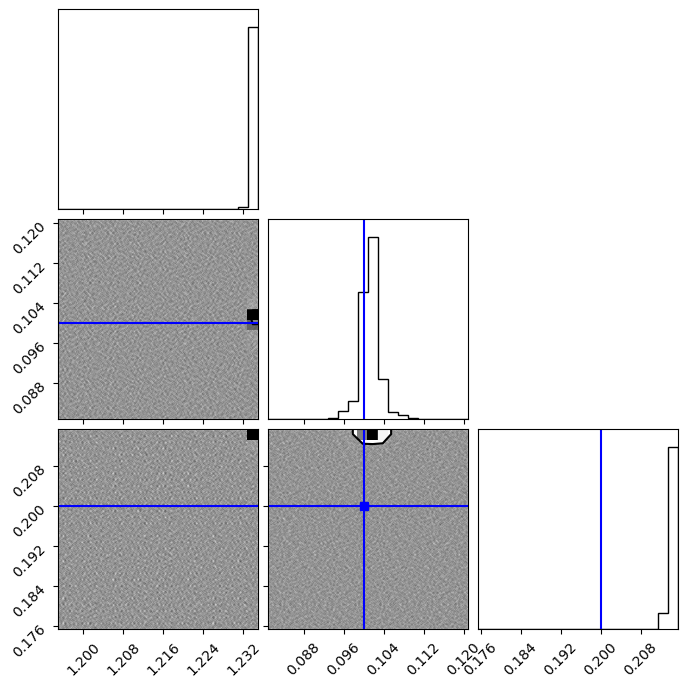

In [ ]:
cor_fig = corner(np.asarray(params_grid),
                 weights=weight,
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue')

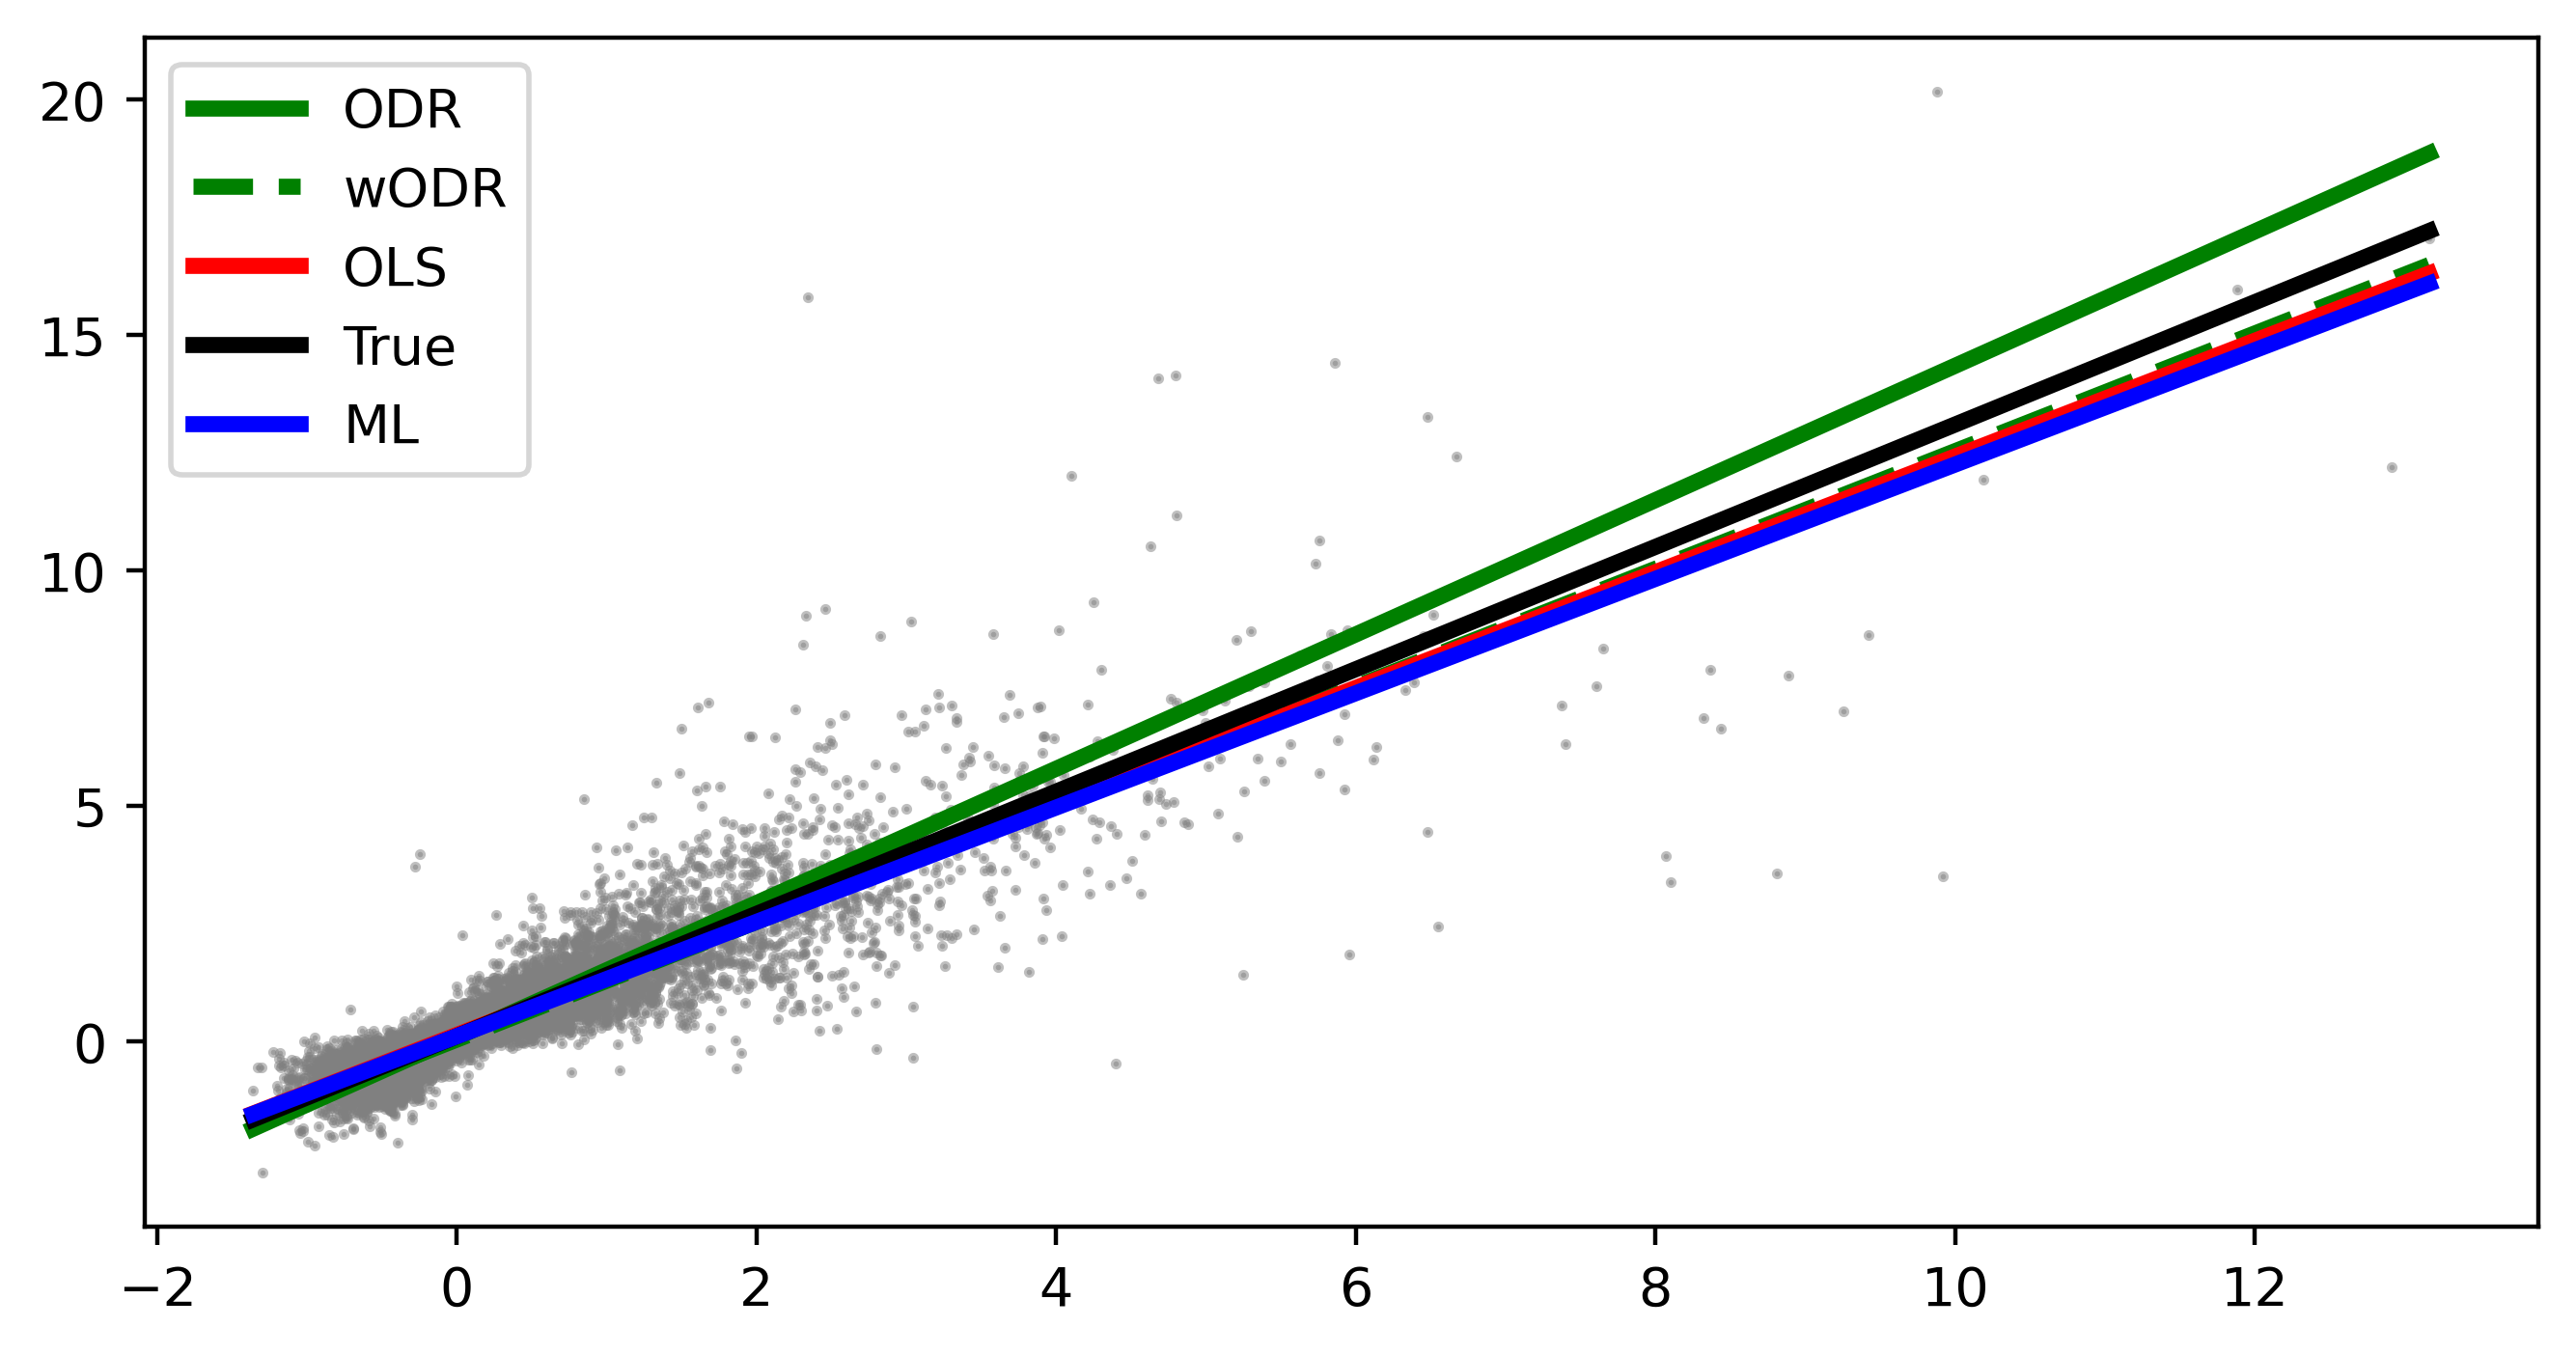

In [ ]:
plt.figure(figsize=(8, 4), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(x_obs.min(), x_obs.max(), 100)
yy = k * xx + b
yy_ML = params_ml[0] * xx + params_ml[1]

plt.plot(xx, yy_ODR, color='green', label='ODR', linestyle='-', lw=3)
plt.plot(xx, yy_wODR, color='green', label='wODR', linestyle='--', lw=3)
plt.plot(xx, yy_OLS, color='red', label='OLS', linestyle='-', lw=3)
plt.plot(xx, yy, color='black', label='True', lw=3)

plt.plot(xx, yy_ML, color='blue', label='ML', linestyle='-', lw=3)

plt.legend()

### KS Based Method

In [ ]:
linear_KS = LinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = linear_KS.fit(x_obs,
                                                 y_obs,
                                                 params_list=[
                                                     np.linspace(0.5, 1.5, 7),
                                                     np.linspace(-0.1, 0.3, 7),
                                                     np.linspace(0.1, 0.3, 5)
                                                 ],
                                                 verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.344 +/- 0.082
b: 0.102 +/- 0.028
sig: 0.197 +/- 0.066


----
k: 1.325 +/- 0.094
b: 0.102 +/- 0.036
sig: 0.196 +/- 0.103


----
k: 1.318 +/- 0.095
b: 0.099 +/- 0.037
sig: 0.205 +/- 0.100


----
k: 1.326 +/- 0.092
b: 0.100 +/- 0.034
sig: 0.201 +/- 0.097


----
k: 1.329 +/- 0.096
b: 0.102 +/- 0.036
sig: 0.194 +/- 0.098


... (3 outputs left out)

----
k: 1.325 +/- 0.097
b: 0.100 +/- 0.035
sig: 0.194 +/- 0.097


----
k: 1.330 +/- 0.093
b: 0.102 +/- 0.036
sig: 0.200 +/- 0.100


----
k: 1.325 +/- 0.093
b: 0.102 +/- 0.036
sig: 0.194 +/- 0.101
max iteration reached


[1.32365876 0.10065826 0.19795248] [0.0897346  0.03473853 0.09408878]


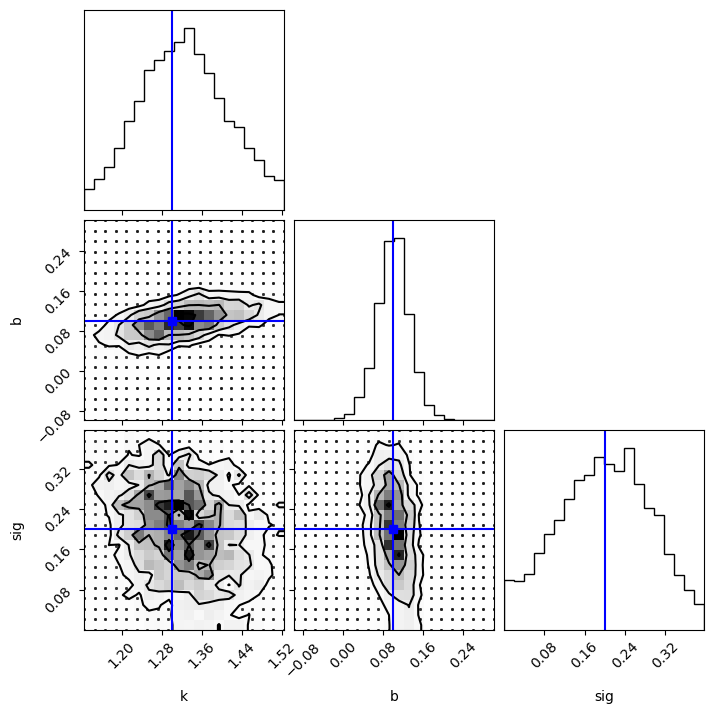

In [ ]:
cor_fig = corner(np.asarray(res_arr[:, :3]),
                 weights=res_arr[:, -1],
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue',
                 labels=['k', 'b', 'sig'])